# 07 — Academic research showcase and GitHub Pages

Build an academically credible, professor-facing README, data catalogue and figure gallery from **real local Hakaluki research outputs**. This notebook does not generate methane measurements, contact Earth Engine, or overwrite the repo README unless you explicitly choose to do so.

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Markdown

ROOT = Path(r"F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project")
assert (ROOT / "config" / "settings.json").exists(), f"Project not found: {ROOT}"
sys.path.insert(0, str(ROOT))
from src.academic_showcase import build

print("Project root:", ROOT)

Project root: F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project


## A. Generate academic preview and GitHub Pages gallery

This extracts actual counts from your completed monthly CSV, inventories the rasters, reads your existing figures and rebuilds the March–June–October SAR comparison from your GeoTIFFs with correctly labelled geographic axes.

In [2]:
REPORT = build(ROOT, publish_root_readme=False)
for key, value in REPORT.items():
    print(f"{key}: {value}")

preview: F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project\README_ACADEMIC_PREVIEW.md
gallery: F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project\docs\index.html
docs: F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project\docs
months: 84
methane_available: 69
rasters: 18
featured_figures: 28
curated_csv: 7
source_monthly_csv: data\processed\hakaluki_monthly_2019_2025.csv
cache_fingerprint: 11d6b74f88543283fc05
generated_utc: 2026-10-13T19:37:45.136655+00:00
methane_note: XCH4 missingness counted, not vetted for native-footprint retrieval quality
status: exploratory_not_field_calibrated
published_root_readme: False


## B. Inspect the README before publication

Be sure that every claim matches your evidence. The status of the watershed polygon, SAR masks, methane data and future calibration is disclosed.

In [3]:
README = ROOT / "README_ACADEMIC_PREVIEW.md"
print("Readme preview:", README)
print(README.read_text(encoding="utf-8")[:6000])

Readme preview: F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project\README_ACADEMIC_PREVIEW.md
# Hakaluki Haor | Wetland inundation and atmospheric methane dynamics

**Reproducible Earth Observation research in northeastern Bangladesh**  
Sentinel-1 SAR · Sentinel-2 · Dynamic World · TROPOMI XCH₄ · CHIRPS · ERA5-Land · GIS · Python · Google Earth Engine

> **Research status: exploratory / ongoing.** Flood masks are low-VV screening products, not validated flood maps. TROPOMI measures atmospheric column methane (XCH₄), not wetland surface methane flux. Local field flux calibration and atmospheric inversion have not yet been completed.

## Research at a glance

| Indicator | Currently documented |
|---|---|
| Study period | 2019–2025 |
| Monthly records | 84 |
| Local GeoTIFF exports inventoried | 18 (not necessarily committed to Git) |
| Months with an ROI XCH₄ value | 69 / 84; retrieval-quality screening remains essential |
| Study-area polygon | User-provided, topologically

## C. Review the generated figures and tables

Public-facing figures: 28
01_monthly_timeseries.png


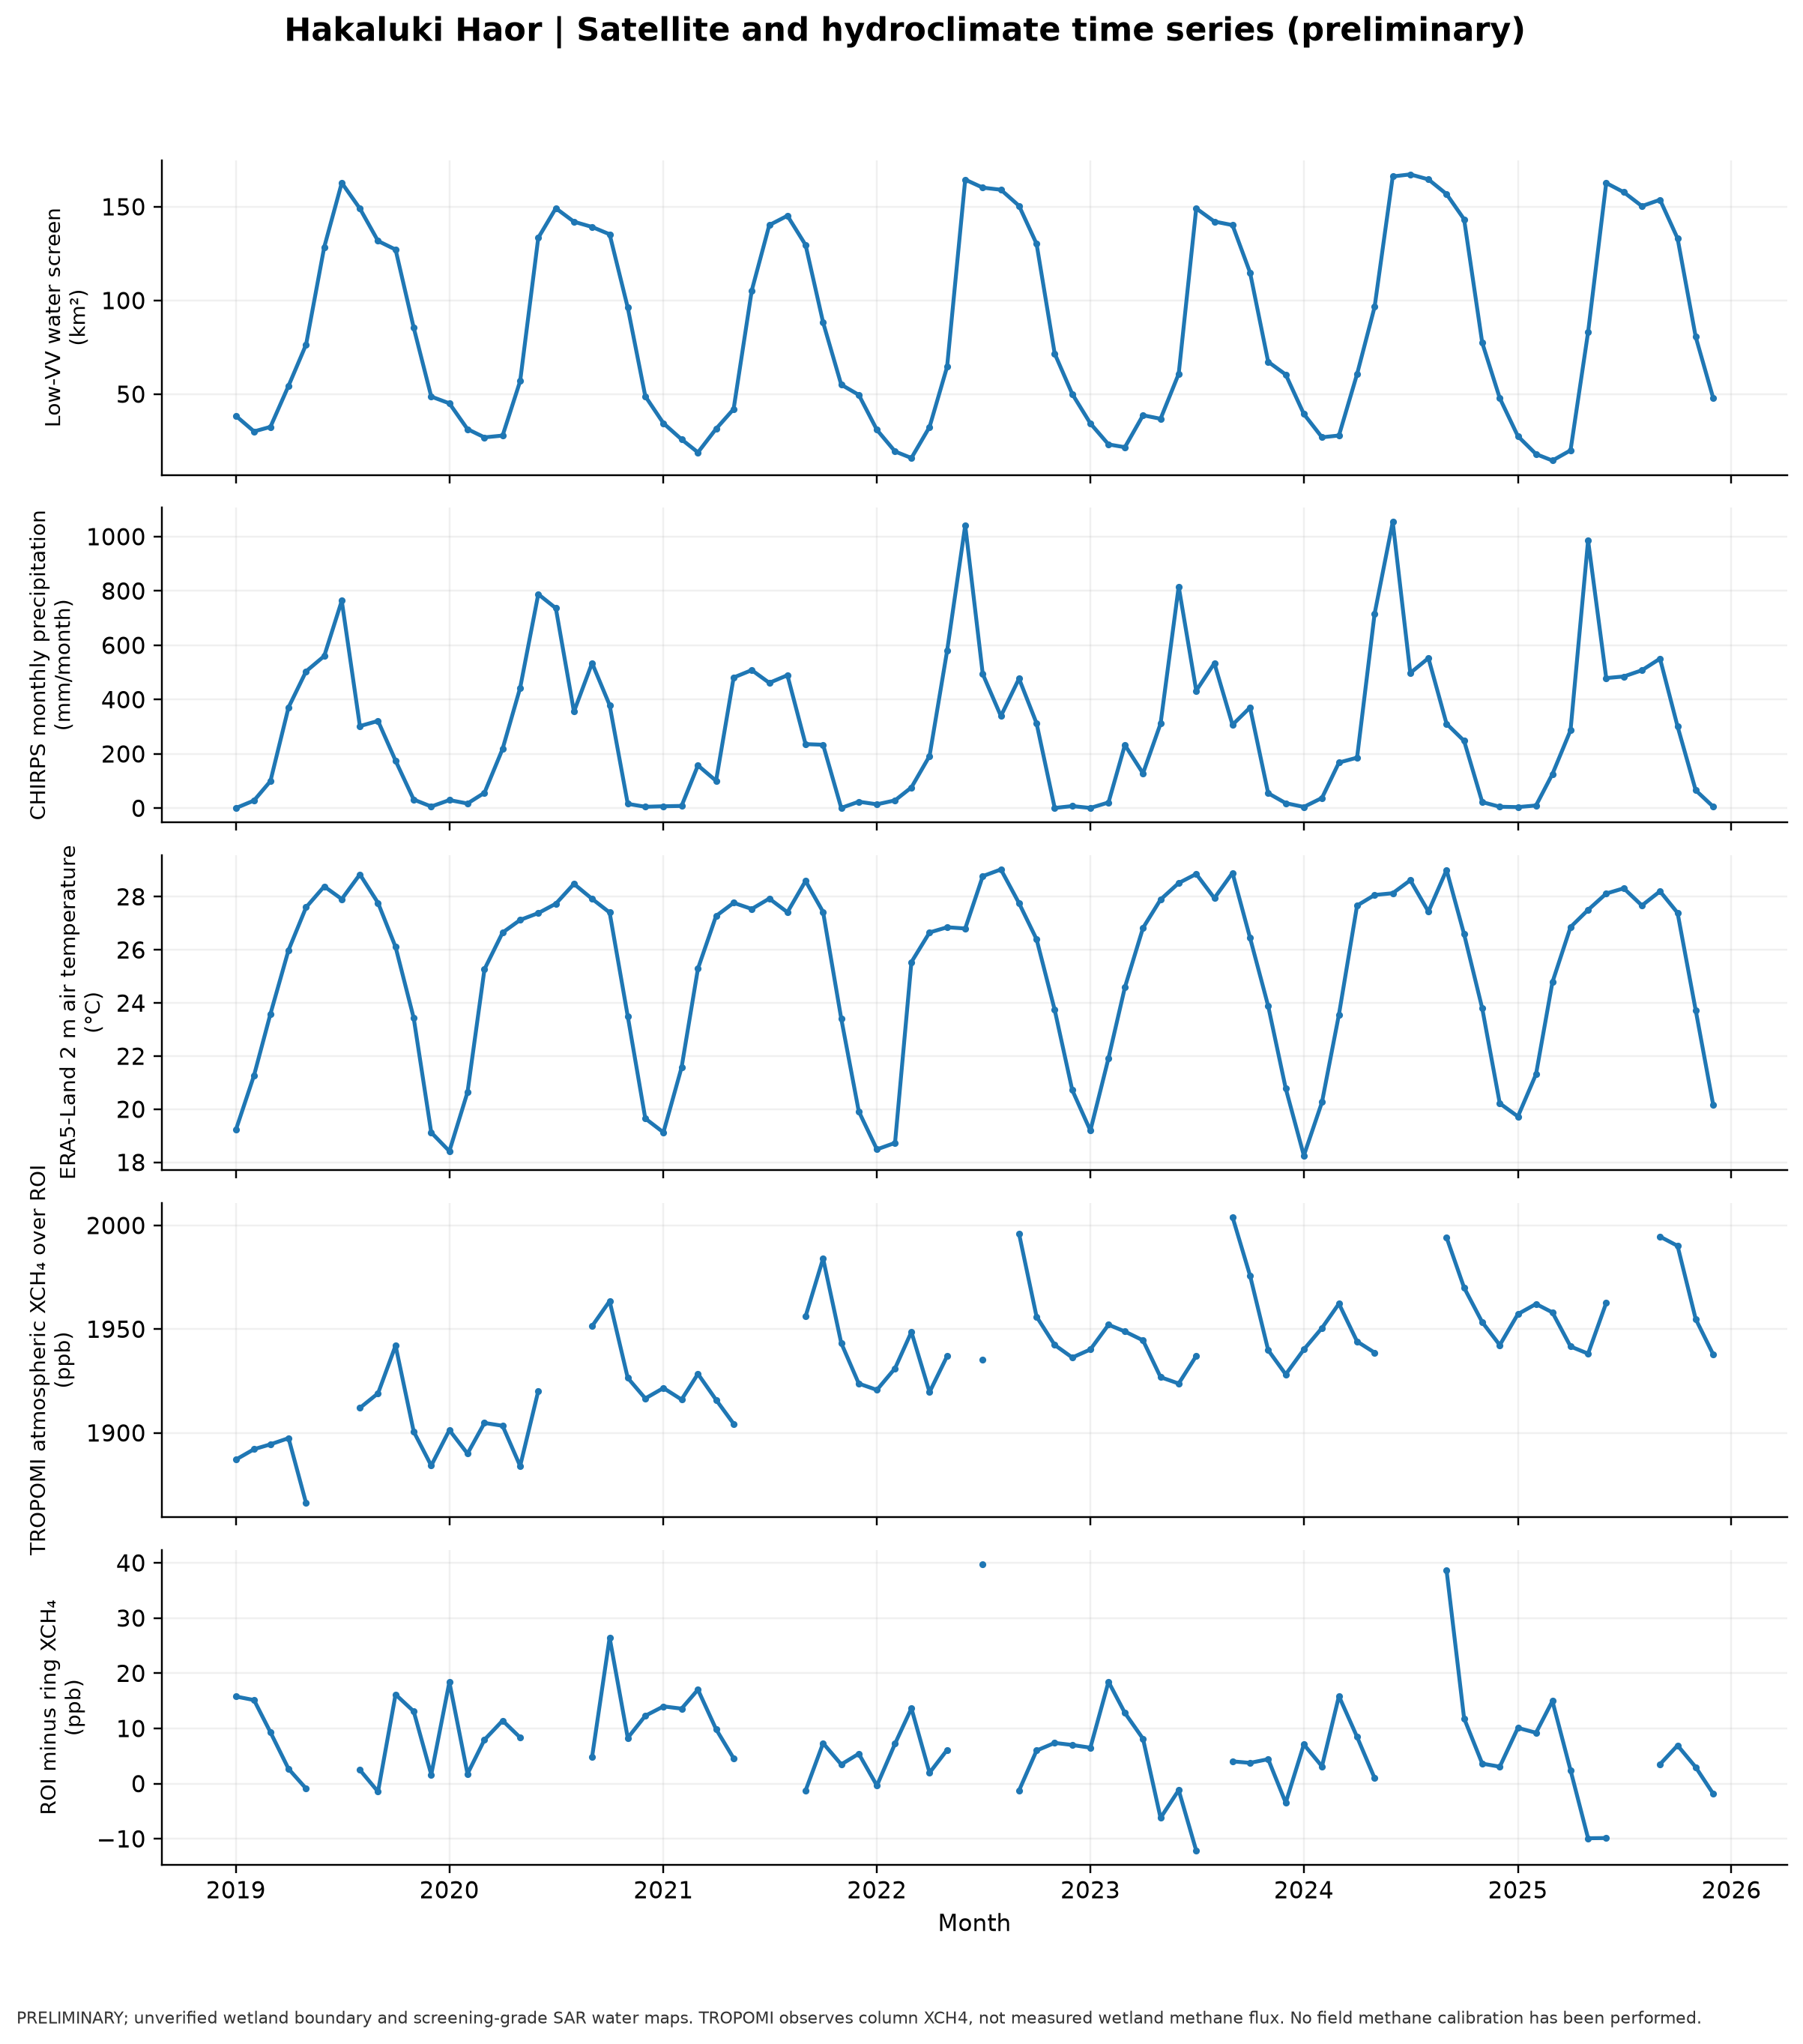

02_data_completeness.png


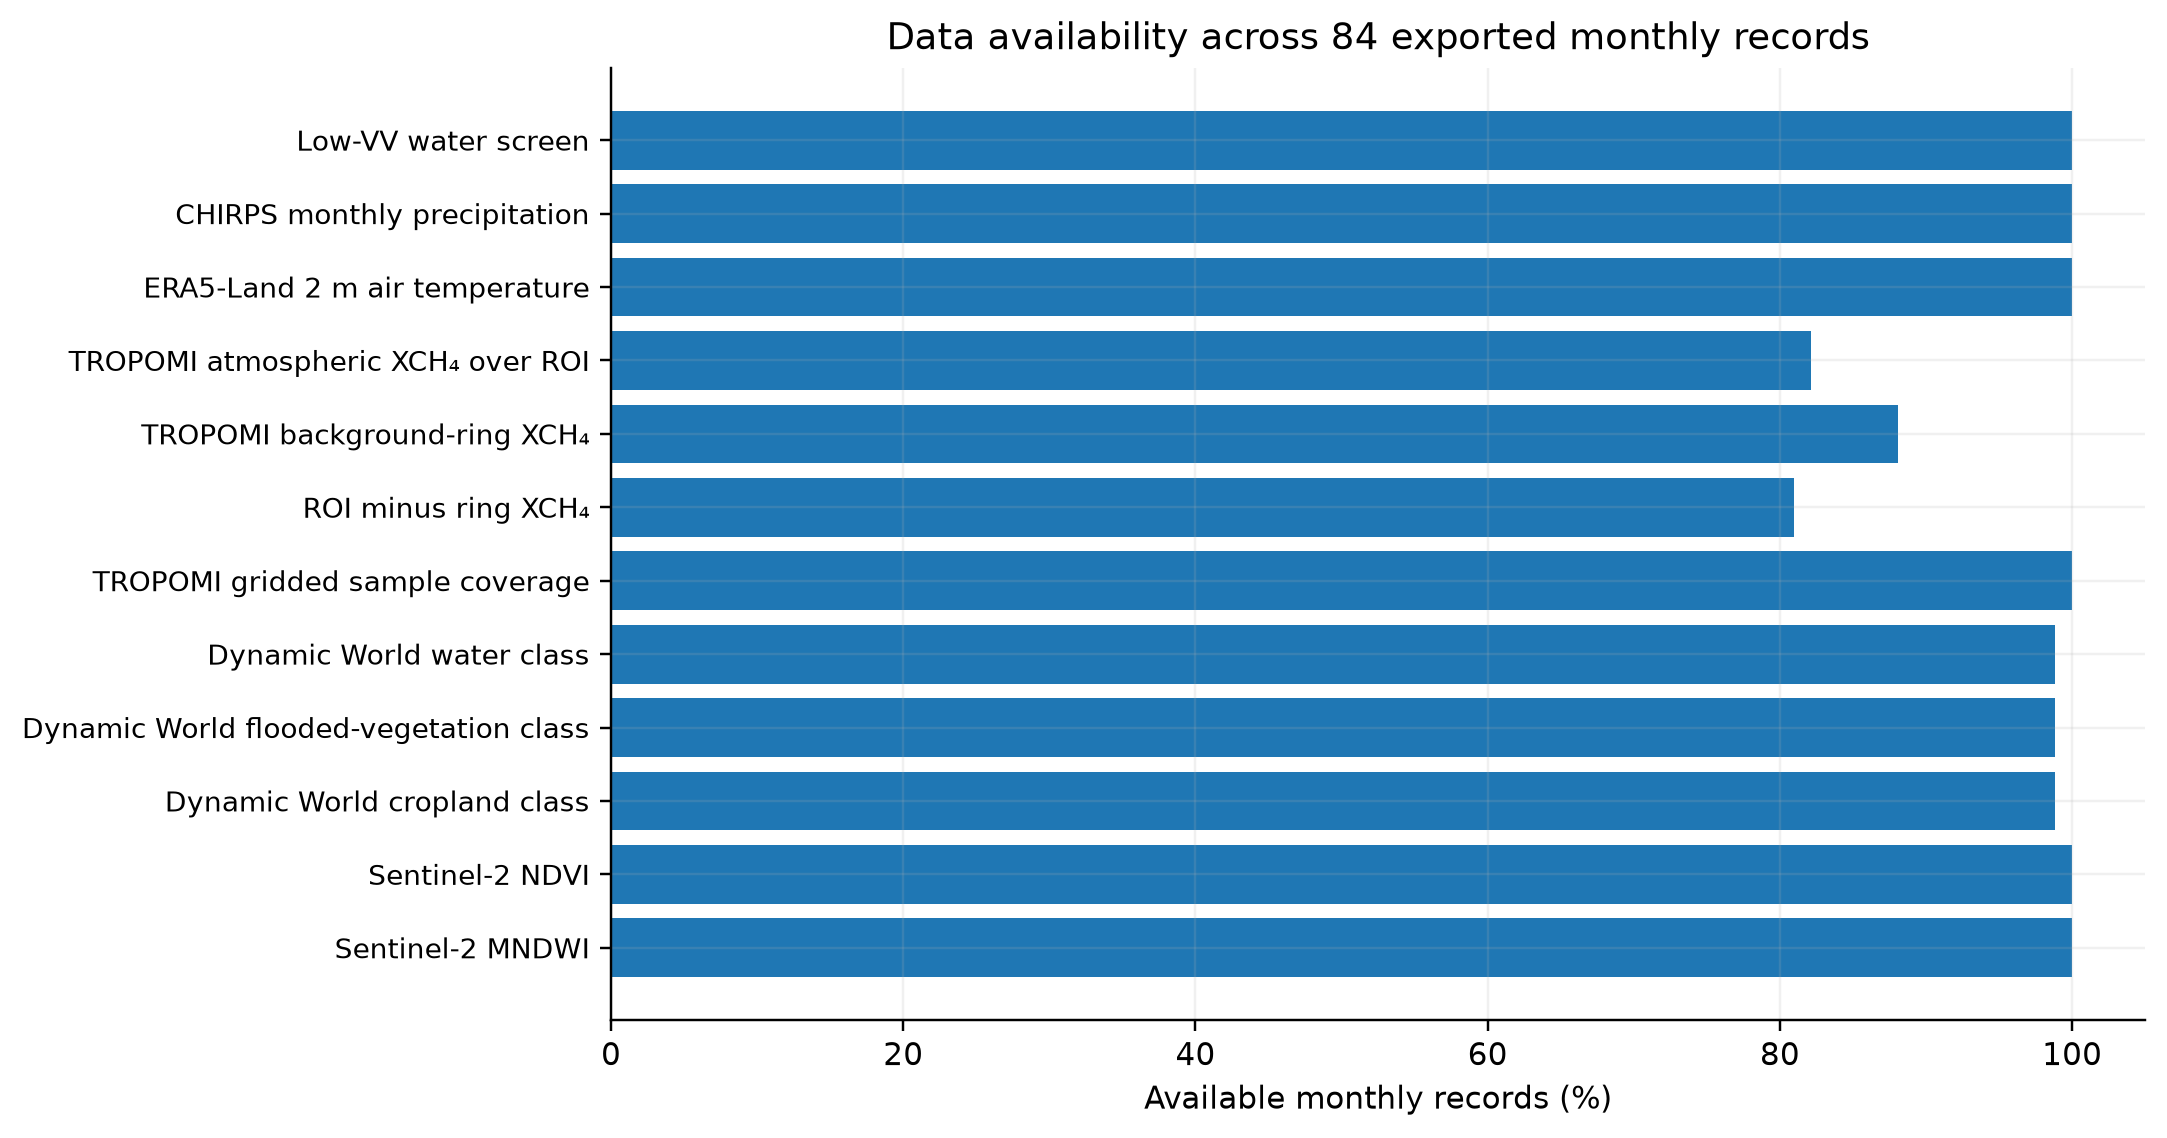

03_monthly_seasonality.png


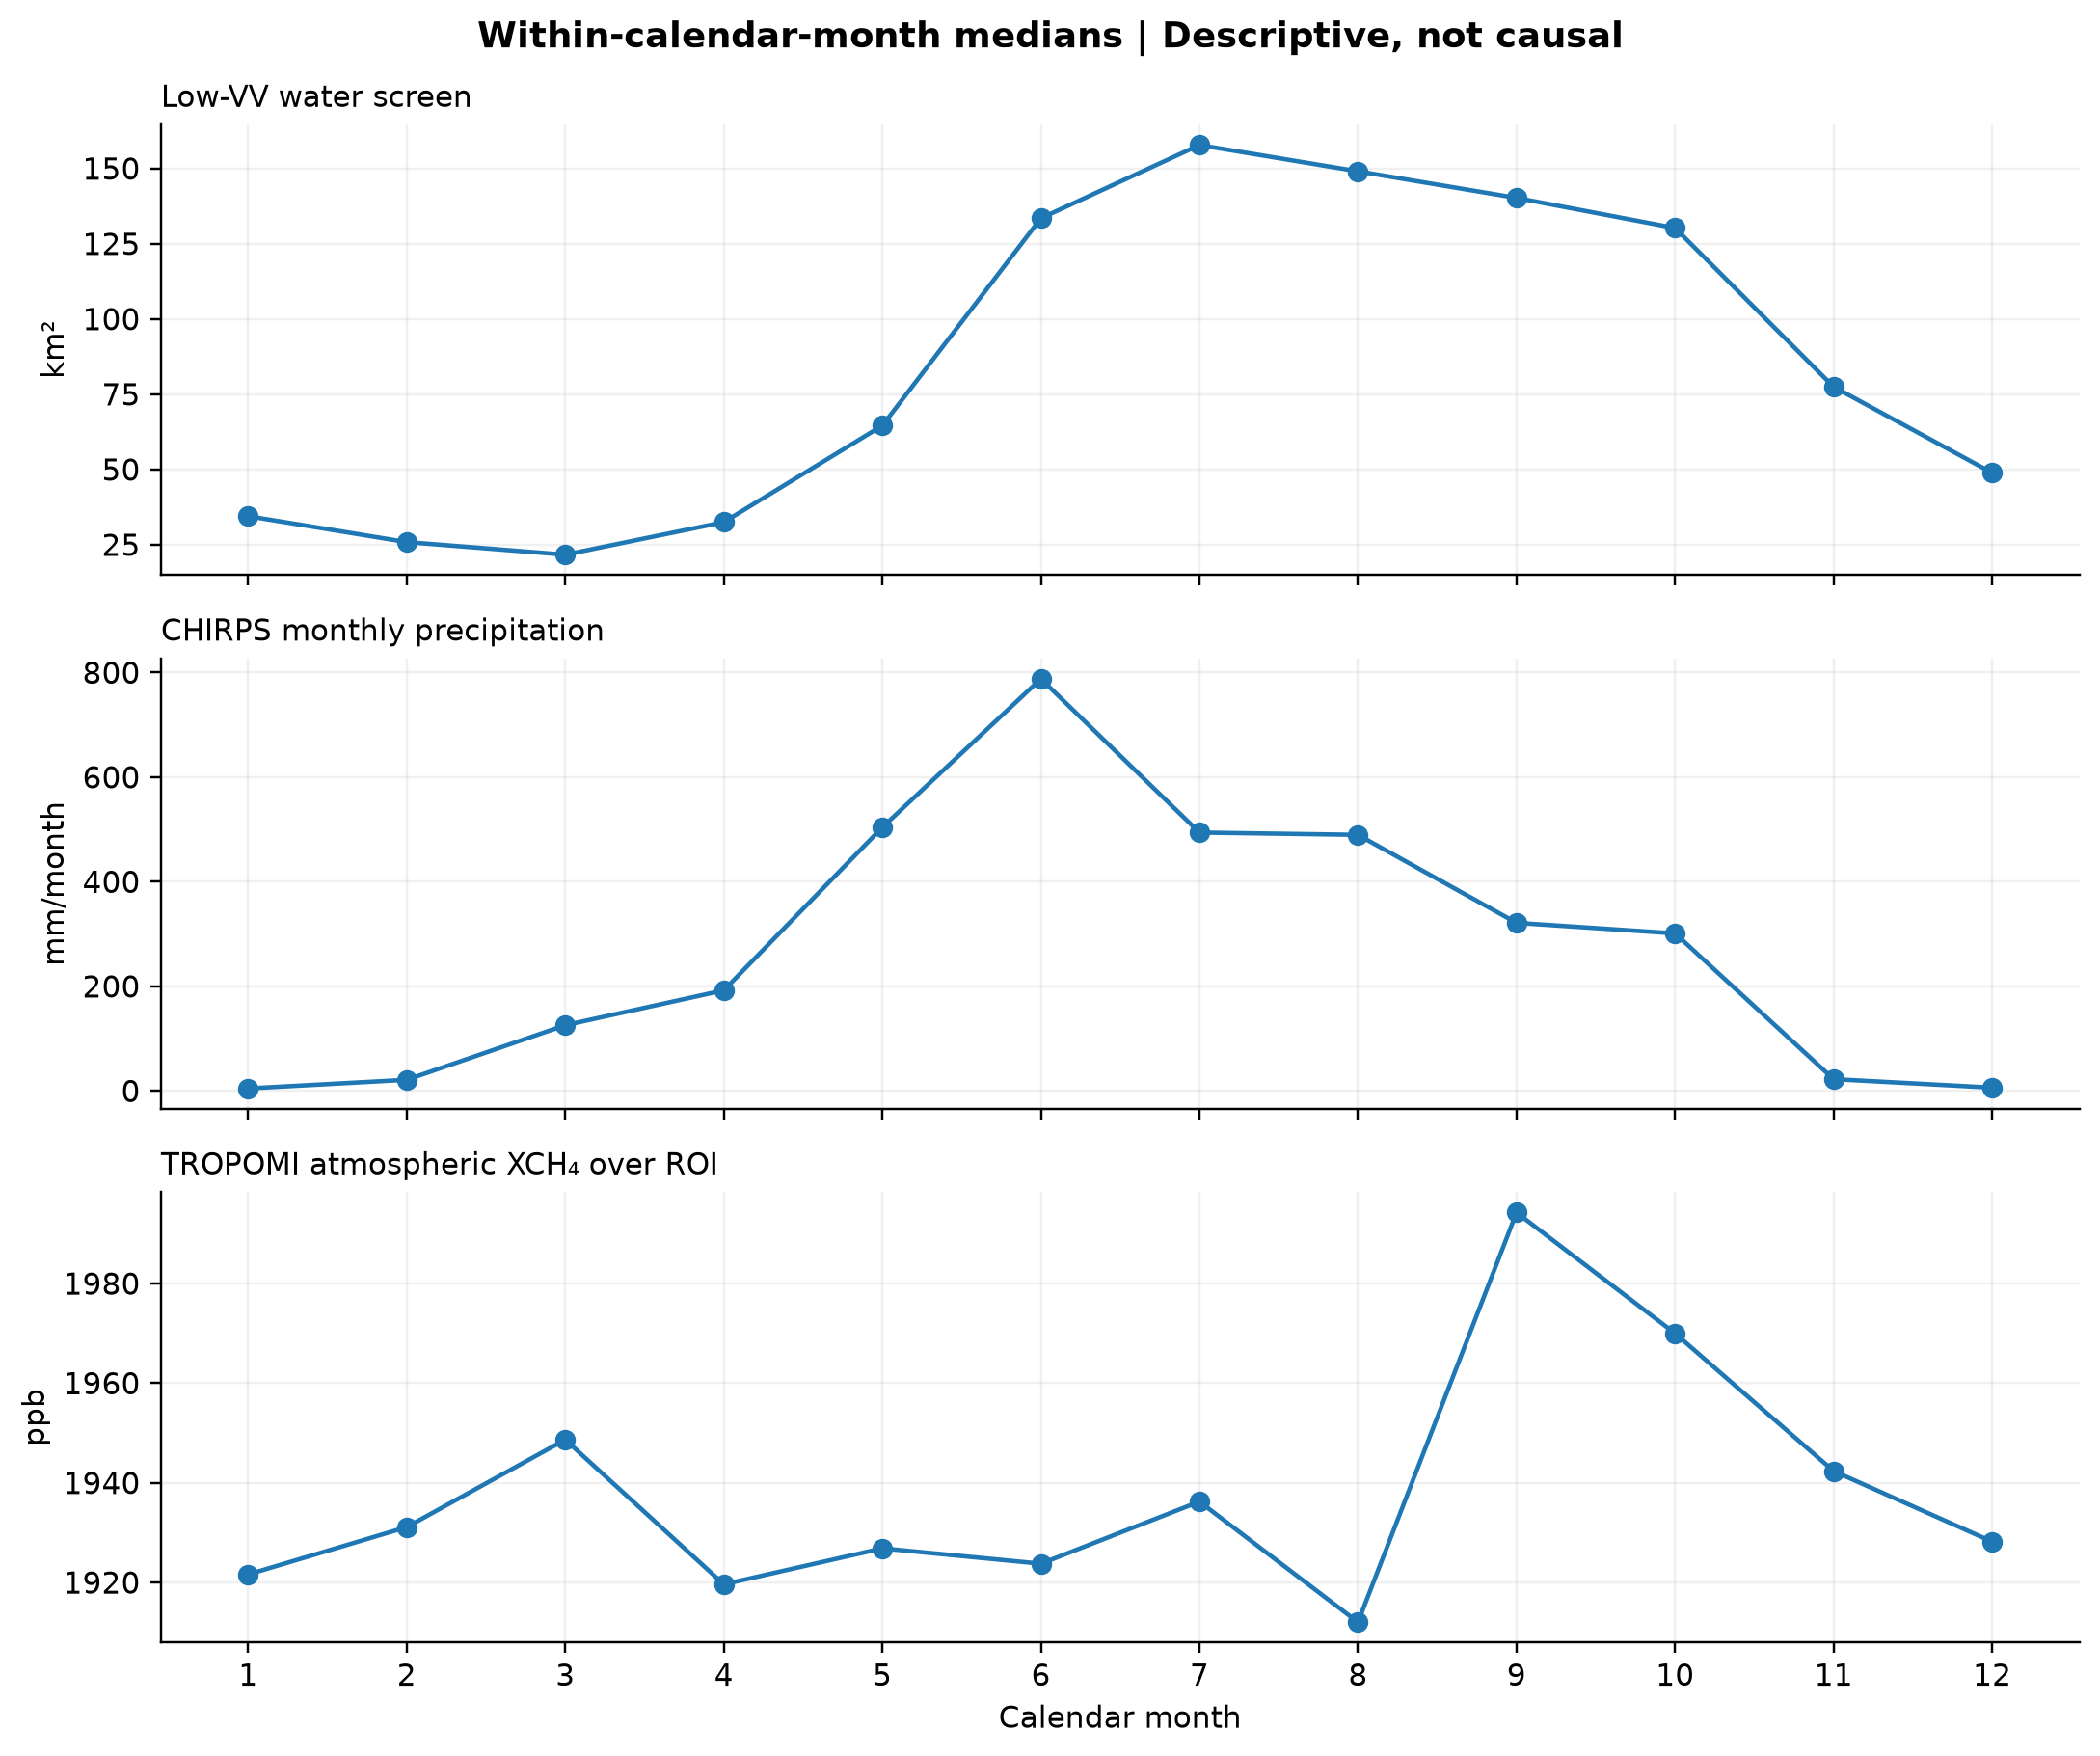

04_exploratory_correlations.png


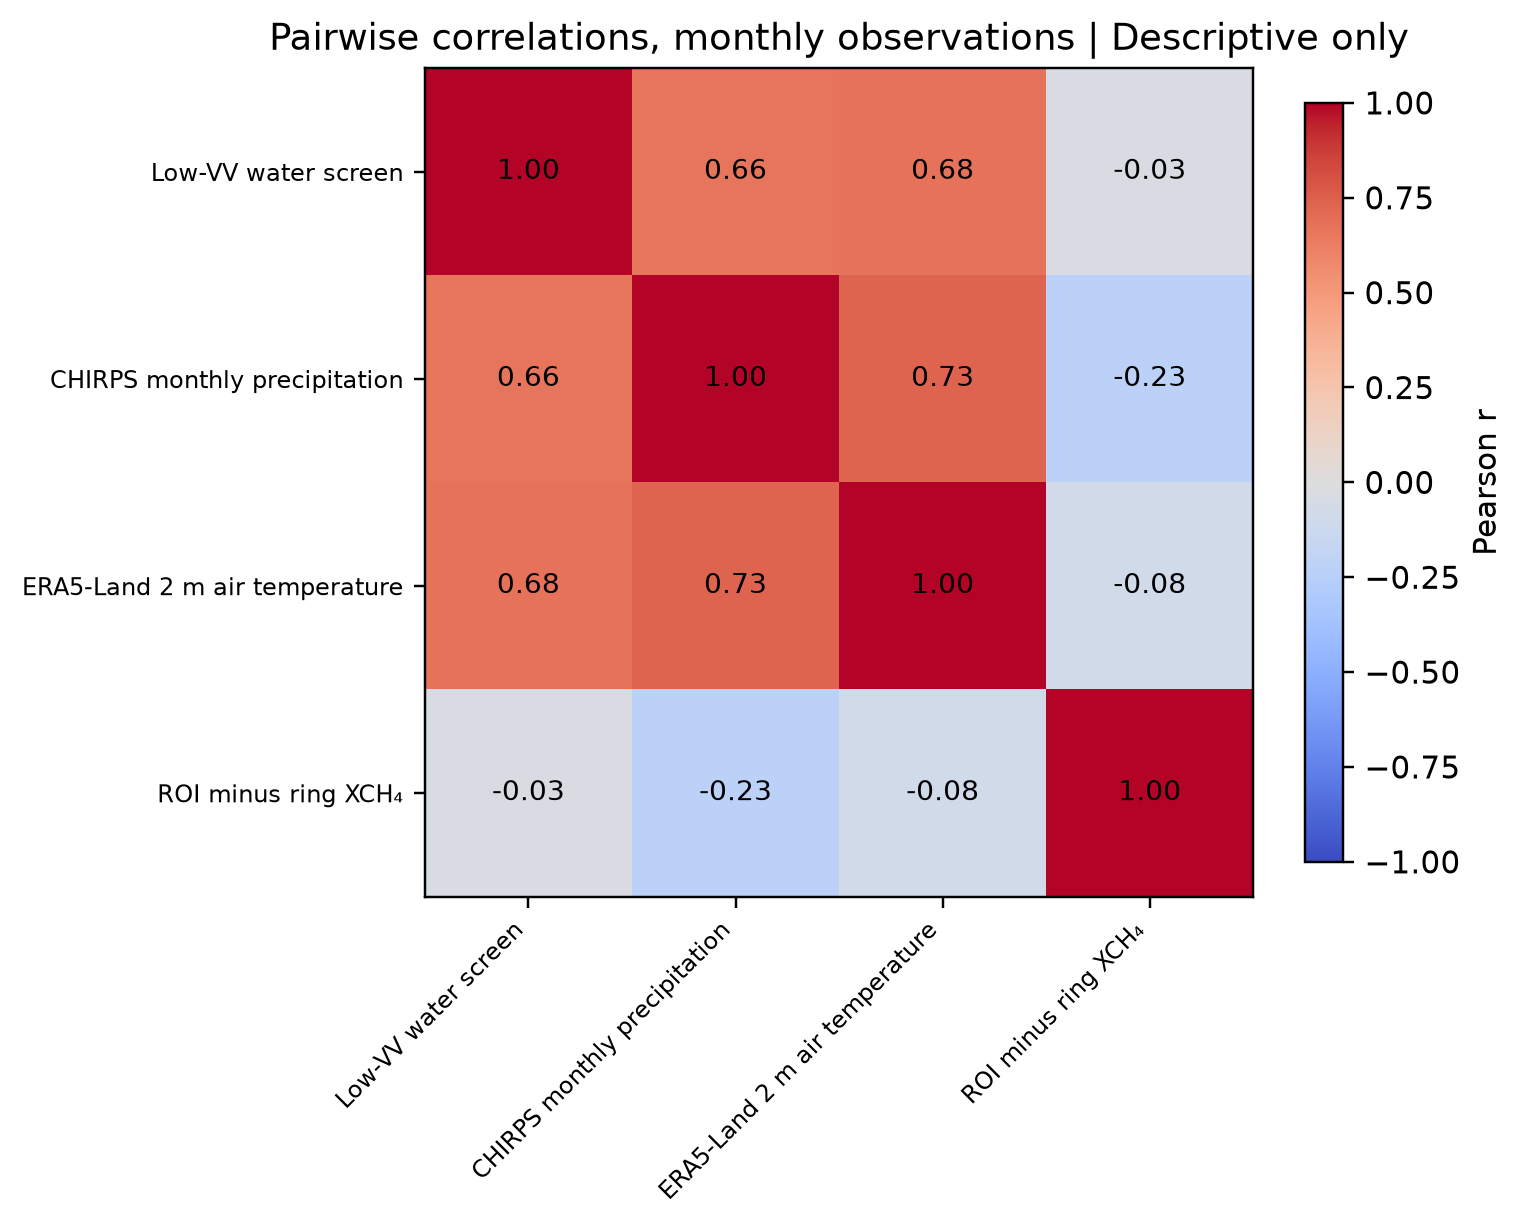

Published curated data catalogue:


,name,kind,status,source,public_file,sha256,notes
0,HAKALUKI_2022_03_CHIRPS_rain.tif,raster,locally_available_not_validated,GEE export,NO: raster stays in results/rasters,b27d949dea44044813739b0fd436185d80d564188482d1...,See original Earth Engine task manifest
1,HAKALUKI_2022_03_DW_class.tif,raster,locally_available_not_validated,GEE export,NO: raster stays in results/rasters,082a75b69a38a42def95907289e05fea4c56f7080236d0...,See original Earth Engine task manifest
2,HAKALUKI_2022_03_ERA5_temp.tif,raster,locally_available_not_validated,GEE export,NO: raster stays in results/rasters,e6bca47b80e09adf6bf9c65d003754df1d5ecbfda8a6b2...,See original Earth Engine task manifest
3,HAKALUKI_2022_03_S2_MNDWI.tif,raster,locally_available_not_validated,GEE export,NO: raster stays in results/rasters,78f792855d725be1751add518a306b39afe2b086189360...,See original Earth Engine task manifest
4,HAKALUKI_2022_03_S2_NDVI.tif,raster,locally_available_not_validated,GEE export,NO: raster stays in results/rasters,816962ec79a6fcce39edcbdf93820c2798808149f06fe4...,See original Earth Engine task manifest
5,HAKALUKI_2022_03_SAR_water.tif,raster,locally_available_not_validated,GEE export,NO: raster stays in results/rasters,c181052cc7f953cab963309e30ce055501e0879b316dc2...,See original Earth Engine task manifest
6,HAKALUKI_2022_06_CHIRPS_rain.tif,raster,locally_available_not_validated,GEE export,NO: raster stays in results/rasters,f4b6889aa2234035665c845282c6d5dc5ee88faf7a74c0...,See original Earth Engine task manifest
7,HAKALUKI_2022_06_DW_class.tif,raster,locally_available_not_validated,GEE export,NO: raster stays in results/rasters,54efb4706c5c6cdb5015db8552151a35b381f3f90183cb...,See original Earth Engine task manifest
8,HAKALUKI_2022_06_ERA5_temp.tif,raster,locally_available_not_validated,GEE export,NO: raster stays in results/rasters,5a81b0eb5f83ae04bd17c5260da24b75b221e35979b893...,See original Earth Engine task manifest
9,HAKALUKI_2022_06_S2_MNDWI.tif,raster,locally_available_not_validated,GEE export,NO: raster stays in results/rasters,4089a7a2b3970782512e02cfe54b20847f1d8635794be6...,See original Earth Engine task manifest


In [4]:
from IPython.display import Image
import pandas as pd
figure_dir = ROOT / "docs" / "assets" / "figures"
figures = sorted(figure_dir.glob("*.png"))
print("Public-facing figures:", len(figures))
for fig in figures[:4]:
    print(fig.name)
    display(Image(filename=str(fig), width=850))
print("Published curated data catalogue:")
display(pd.read_csv(ROOT / "docs" / "data_catalog.csv").head(15))

## D. Publication is optional

After reviewing the output, change the flag below to `True` to replace the main repository README. The builder backs up the original to `README.before_academic_showcase.md` on first use. Never commit API tokens or local secrets.

In [8]:
PUBLISH_ROOT_README = True
if PUBLISH_ROOT_README:
    result = build(ROOT, publish_root_readme=True)
    print("Published repository README:", ROOT / "README.md")
else:
    print("Preview only. Existing README.md preserved.")

Published repository README: F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project\README.md


## E. View and publish the gallery

Open `docs/index.html` locally. When ready, commit your reviewed `docs/`, `research_docs/`, notebooks and code to GitHub. To enable GitHub Pages, choose **Settings → Pages → Deploy from branch → main → /docs**. See `research_docs/GITHUB_PUBLISHING_GUIDE.md`.

In [6]:
print("Open:", ROOT / "docs" / "index.html")
print("Read:", ROOT / "research_docs" / "GITHUB_PUBLISHING_GUIDE.md")

Open: F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project\docs\index.html
Read: F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project\research_docs\GITHUB_PUBLISHING_GUIDE.md


In [7]:

from pathlib import Path
import webbrowser

ROOT = Path(
    r"F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project"
)

portfolio = ROOT / "docs" / "index.html"

assert portfolio.exists(), "Portfolio HTML not found"

webbrowser.open(portfolio.as_uri())

print("Portfolio opened:", portfolio)


Portfolio opened: F:\Wetland Test\Hakaluki_Haor_Wetland_Test_Jupyter_GEE_Project\docs\index.html
